In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.model_selection as train_test_split

In [30]:
df=pd.read_csv("loan_approval_data.csv")

In [31]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


#handling missing values

In [32]:
categ_columns= df.select_dtypes(include=["object"]).columns
numeric_columns= df.select_dtypes(include=["number"]).columns


In [33]:
categ_columns

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [34]:
numeric_columns

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [35]:
from sklearn.impute import SimpleImputer

num_imp= SimpleImputer(strategy='mean')
df[numeric_columns]=num_imp.fit_transform(df[numeric_columns])
cat_imp=SimpleImputer(strategy='most_frequent')
df[categ_columns]=cat_imp.fit_transform(df[categ_columns])

In [36]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [37]:
df.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

#EDA


Text(0.5, 1.0, 'loan approved or not')

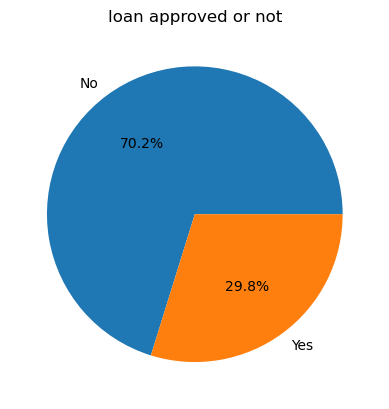

In [38]:
class_count=df["Loan_Approved"].value_counts()

plt.pie(class_count,labels=[ "No" , "Yes" ],autopct="%1.1f%%")
plt.title("loan approved or not")


<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

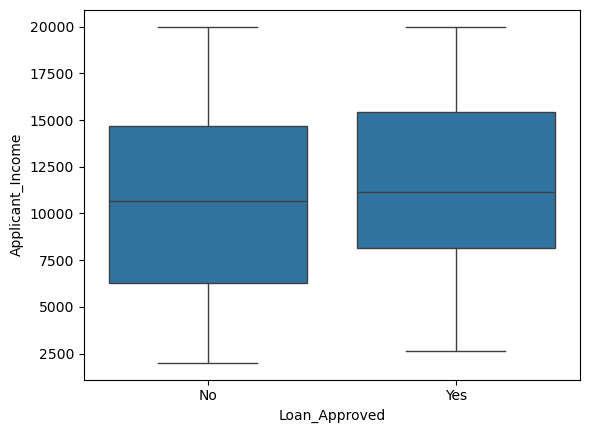

In [39]:

sns.boxplot(data=df,
            x="Loan_Approved",
            y="Applicant_Income"
           )



<Axes: xlabel='Loan_Approved', ylabel='Existing_Loans'>

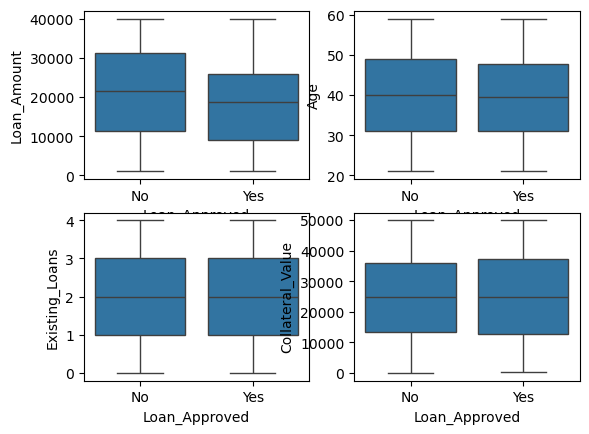

In [40]:
fig, axes=plt.subplots(2,2)
sns.boxplot(ax=axes[0,0],data=df,x="Loan_Approved",y="Loan_Amount")
sns.boxplot(ax=axes[0,1],data=df,x="Loan_Approved",y="Age")
sns.boxplot(ax=axes[1,1],data=df,x="Loan_Approved",y="Collateral_Value")
sns.boxplot(ax=axes[1,0],data=df,x="Loan_Approved",y="Existing_Loans")
           

#ENCODING


In [41]:
df.head()
categ_columns

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [42]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le=LabelEncoder()
df["Education_Level"]=le.fit_transform(df["Education_Level"])
df["Loan_Approved"]=le.fit_transform(df["Loan_Approved"])
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [43]:
cols=["Employment_Status","Marital_Status","Loan_Purpose","Gender","Property_Area","Employer_Category"]
ohe=OneHotEncoder(drop="first",sparse_output=False,handle_unknown='ignore')
encoded=ohe.fit_transform(df[cols])
encoded_df=pd.DataFrame(encoded,columns=ohe.get_feature_names_out(cols),index=df.index)

In [44]:
encoded_df

,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Gender_Male,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
996,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
997,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
998,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


In [45]:
df=pd.concat([df.drop(columns=cols),encoded_df],axis=1)

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_ID                     1000 non-null   float64
 1   Applicant_Income                 1000 non-null   float64
 2   Coapplicant_Income               1000 non-null   float64
 3   Age                              1000 non-null   float64
 4   Dependents                       1000 non-null   float64
 5   Credit_Score                     1000 non-null   float64
 6   Existing_Loans                   1000 non-null   float64
 7   DTI_Ratio                        1000 non-null   float64
 8   Savings                          1000 non-null   float64
 9   Collateral_Value                 1000 non-null   float64
 10  Loan_Amount                      1000 non-null   float64
 11  Loan_Term                        1000 non-null   float64
 12  Education_Level      

#CORELATION HEATMAP

nums_cols=df.select_dtypes(include="number")
nums_cols.corr()["Coapplicant_Income"].sort_values(ascending=False)

<Axes: >

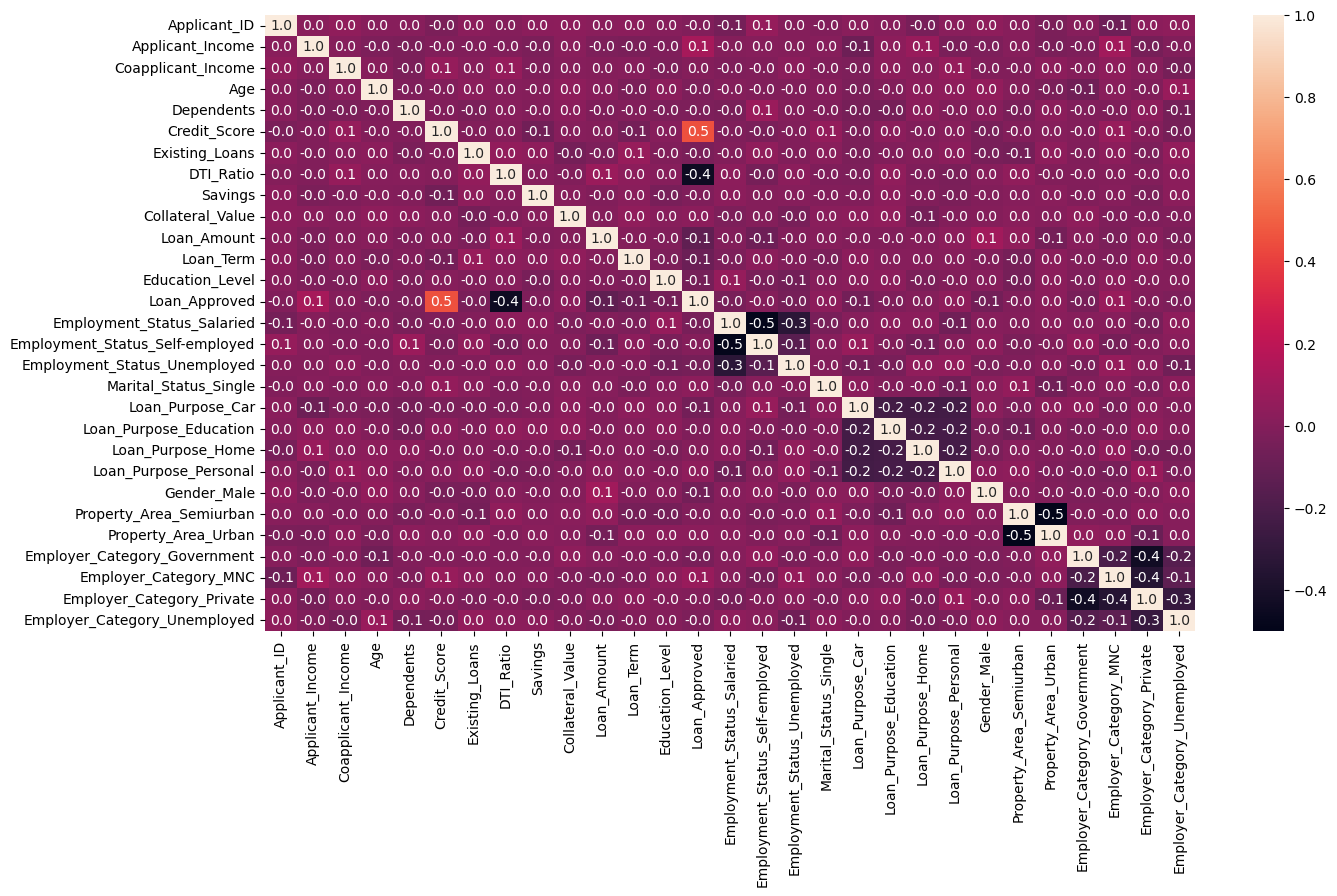

In [81]:
plt.figure(figsize=(15,8))
sns.heatmap(
    nums_cols.corr(),
    annot=True,
    fmt=".1f"
    
)

#TRAIN-TEST-SPLIT

In [62]:
X=df.drop("Loan_Approved",axis=1)
y=df["Loan_Approved"]


In [70]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


In [71]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scales=scaler.fit_transform(X_train)
X_test_scales=scaler.transform(X_test)

In [74]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score,confusion_matrix

lg_model= LogisticRegression()
lg_model.fit(X_train_scales,y_train)
y_pred=lg_model.predict(X_test_scales)
#evaluate


In [75]:
print("precision",precision_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred))
print("CM",confusion_matrix(y_test,y_pred))   

precision 0.7868852459016393
accuracy_score 0.87
CM [[126  13]
 [ 13  48]]


In [76]:
from sklearn.neighbors import KNeighborsClassifier
neigh = KNeighborsClassifier(n_neighbors=3)
neigh.fit(X_train_scales, y_train)
y_pred=neigh.predict(X_test_scales)


In [77]:
print("precision",precision_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred))
print("CM",confusion_matrix(y_test,y_pred))   

precision 0.5961538461538461
accuracy_score 0.745
CM [[118  21]
 [ 30  31]]


In [79]:
from sklearn.naive_bayes import GaussianNB
nb_model= GaussianNB()
nb_model.fit(X_train_scales,y_train)
y_pred=nb_model.predict(X_test_scales)
print("precision",precision_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred))
print("CM",confusion_matrix(y_test,y_pred))   

precision 0.8035714285714286
accuracy_score 0.865
CM [[128  11]
 [ 16  45]]


In [98]:
df["DTI_Ratio_sq"]=df["DTI_Ratio"]**2
df["Credit_Score_sq"]=df["Credit_Score"]**2
df["Applicant_Income_lg"]=np.log1p(df["Applicant_Income"])
X=df.drop(columns=["Credit_Score","DTI_Ratio","Loan_Approved"])
y=df["Loan_Approved"]

In [99]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


In [100]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scales=scaler.fit_transform(X_train)
X_test_scales=scaler.transform(X_test)

In [101]:
from sklearn.naive_bayes import GaussianNB
nb_model= GaussianNB()
nb_model.fit(X_train_scales,y_train)
y_pred=nb_model.predict(X_test_scales)
print("precision",precision_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred))
print("CM",confusion_matrix(y_test,y_pred))   

precision 0.8076923076923077
accuracy_score 0.855
CM [[129  10]
 [ 19  42]]
